In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
### 데이터 적재 및 구조화

def load_data(file_path: str) -> pd.DataFrame:
    df = pd.read_excel(file_path)
    print(f"[불러오기 완료] 행: {df.shape[0]}개, 열: {df.shape[1]}개")
    return df

# 데이터 기본 정보 확인
def check_basic_info(df: pd.DataFrame) -> None:

    print("\n=== 데이터 미리보기 ===")
    print(df.head())
 
    print("\n=== 컬럼별 데이터 타입 ===")
    print(df.dtypes)
 
    print("\n=== 컬럼별 결측치 개수 ===")
    print(df.isnull().sum())

st_raw_data = load_data("./data/raw/structured_dataset/Online Retail.xlsx")
raw = st_raw_data.copy() # 추후 전처리 전후 비교

check_basic_info(st_raw_data)

[불러오기 완료] 행: 541909개, 열: 8개

=== 데이터 미리보기 ===
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  

=== 컬럼별 데이터 타입 ===
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
Inv

수치형 변수 분포
Quantity
기술통계: count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64
UnitPrice
기술통계: count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64


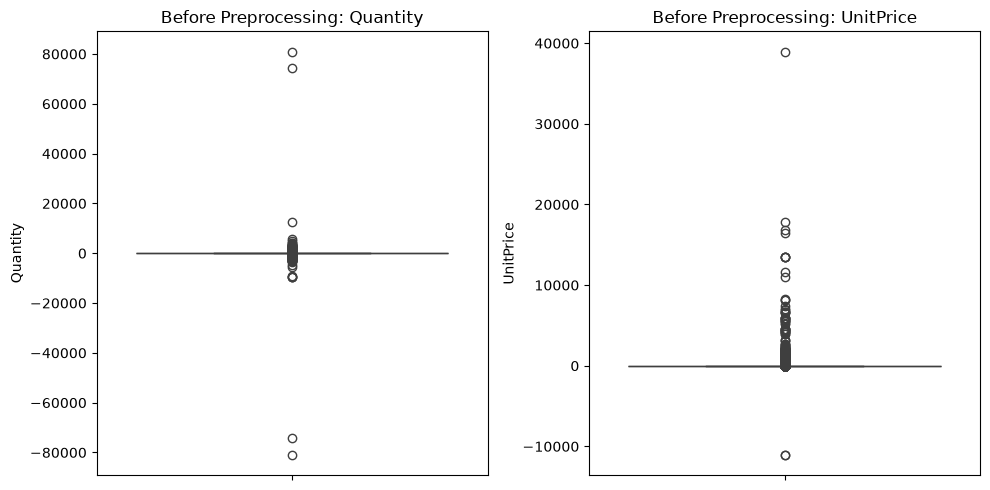

InvoiceDate 분포
InvoiceDate
중복 개수: 518649개
최빈값 : 2011-10-31 14:41:00
최빈값의 빈도수 : 1114
최빈값의 비율 : 0.2


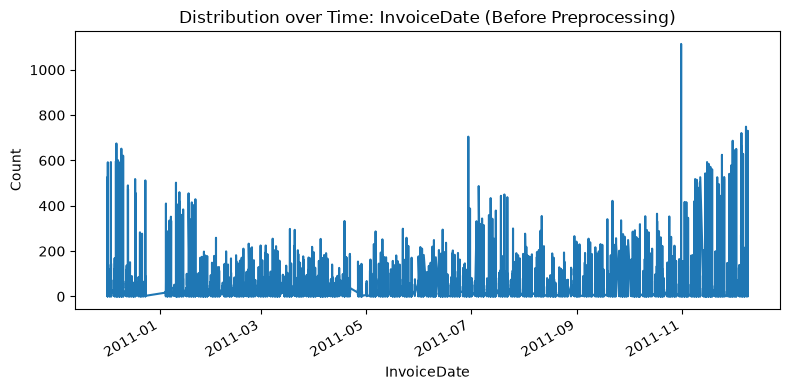

명목형 변수 파악
                    최빈값      빈도  비율(%)  고유값 수   중복 개수
Country  United Kingdom  495478   91.4     38  540279


In [43]:
## 프로파일링 및 EDA, 전처리 전 시각화

# 수치형 변수 시각화

num_cols = ["Quantity", "UnitPrice"]  

fig, axes = plt.subplots(1, len(num_cols), figsize=(5 * len(num_cols), 5))

print("="*20)

print("수치형 변수 분포")

for i, col in enumerate(num_cols):
    sns.boxplot(data=st_raw_data, y=col, ax=axes[i])
    axes[i].set_title(f"Before Preprocessing: {col}")
    print(f"{col}")
    print(f"기술통계: {st_raw_data[col].describe()}")
    print("="*20)

plt.tight_layout()
plt.show()

print("="*20)

# 날짜 변수 시각화

date_col = "InvoiceDate"  

fig, ax = plt.subplots(figsize=(8, 4))
st_raw_data[date_col].value_counts().sort_index().plot(kind="line", ax=ax)
ax.set_title(f"Distribution over Time: {date_col} (Before Preprocessing)")
ax.set_ylabel("Count")

print("InvoiceDate 분포")

print(f"{date_col}")
print(f"중복 개수: {st_raw_data[date_col].duplicated().sum()}개")
print(f"최빈값 : {st_raw_data[date_col].mode().iloc[0]}")
print(f"최빈값의 빈도수 : {st_raw_data[date_col].value_counts().max()}")
print(f"최빈값의 비율 : {round(st_raw_data[date_col].value_counts(normalize=True).max() * 100, 1)}")

print("="*20)

plt.tight_layout()
plt.show()

print("="*20)

# 명목형 변수 파악
cat_cols = st_raw_data.select_dtypes(include=["string"]).columns
print("명목형 변수 파악")
print("="*20)

summary = pd.DataFrame({
    "최빈값": [st_raw_data[c].mode().iloc[0] for c in cat_cols],
    "빈도": [st_raw_data[c].value_counts().max() for c in cat_cols],
    "비율(%)": [round(st_raw_data[c].value_counts(normalize=True).max() * 100, 1) for c in cat_cols],
    "고유값 수": [st_raw_data[c].nunique() for c in cat_cols],
    "중복 개수" : [st_raw_data[col].duplicated().sum() for c in cat_cols]
}, index=cat_cols)

print(summary)

In [44]:
## 특이값 검사

# 수치형 변수

num_cols = ["Quantity", "UnitPrice"]  

for col in num_cols:
    print(f"{col} 음수나 터무니없이 큰 값 추출")

    # 음수나 터무니없이 큰 값 추출
    print("="*20)
    unusual_rows = st_raw_data[(st_raw_data[col] <= 0) | (st_raw_data[col] > 10000)]
    print(unusual_rows[col].head())
    print("="*20)

# 명목형 변수

# InvoiceNo 특이값
invalid_pattern = ~st_raw_data["InvoiceNo"].astype(str).str.match(r"^(C?\d{6})$", na=False)
print("InvoiceNo 특이값")
print(st_raw_data[invalid_pattern]["InvoiceNo"].head(5))
print("="*20)

# StockCode 특이값
invalid_pattern = ~st_raw_data["StockCode"].astype(str).str.match(r"^\d{5}$", na=False)
print("StockCode 특이값")
print(st_raw_data[invalid_pattern]["StockCode"].head(5))
print("="*20)

# CustomerID 특이값
invalid_pattern = ~st_raw_data["CustomerID"].astype(str).str.match(r"^\d{5}$", na=False)
print("CustomerID 특이값")
print(st_raw_data[invalid_pattern]["CustomerID"].head(5))
print("="*20)


Quantity 음수나 터무니없이 큰 값 추출
141    -1
154    -1
235   -12
236   -24
237   -24
Name: Quantity, dtype: int64
UnitPrice 음수나 터무니없이 큰 값 추출
622     0.0
1970    0.0
1971    0.0
1972    0.0
1987    0.0
Name: UnitPrice, dtype: float64
InvoiceNo 특이값
299982    A563185
299983    A563186
299984    A563187
Name: InvoiceNo, dtype: object
StockCode 특이값
0     85123A
2     84406B
3     84029G
4     84029E
45      POST
Name: StockCode, dtype: object
CustomerID 특이값
0    17850.0
1    17850.0
2    17850.0
3    17850.0
4    17850.0
Name: CustomerID, dtype: float64


In [ ]:
# 주요 컬럼 타입 강제 변환
# StockCode, InvoiceNo: 혼합 타입 통일 + 결측 유지
for col in ['StockCode', 'InvoiceNo']:
    st_raw_data[col] = st_raw_data[col].astype('string').str.strip()

# Description: 결측 유지한 채 공백 제거
st_raw_data['Description'] = st_raw_data['Description'].astype('string').str.strip()

st_raw_data['Quantity'] = pd.to_numeric(st_raw_data['Quantity'], errors='coerce')
st_raw_data['InvoiceDate'] = pd.to_datetime(st_raw_data['InvoiceDate'], errors='coerce')
st_raw_data['UnitPrice'] = pd.to_numeric(st_raw_data['UnitPrice'], errors='coerce')


# 공백 문자 및 가짜 결측치를 np.nan으로 치환
st_raw_data.replace(r'^\s*$', np.nan, regex=True, inplace=True)


[불러오기 완료] 행: 541909개, 열: 8개


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [54]:
## 취소 주문행 검사 
raw = st_raw_data.copy()

is_cancelled = raw['InvoiceNo'].astype(str).str.upper().str.startswith('C')
price = pd.to_numeric(raw['UnitPrice'], errors='coerce')
quantity = pd.to_numeric(raw['Quantity'], errors='coerce')

print("전체 행                         :", len(raw))
print("취소 주문(C) 행                 :", is_cancelled.sum())

print("="*50)

print("UnitPrice <= 0 행                :", (price <= 0).sum())
print("취소 주문 이면서 UnitPrice <= 0  :", (is_cancelled & (price <= 0)).sum())
print("취소 주문 이면서 UnitPrice > 0   :", (is_cancelled & (price > 0)).sum())
print("비취소 주문 이면서 UnitPrice <= 0:", (~is_cancelled & (price <= 0)).sum())

print("="*50)

print("Quantity <= 0 행                :", (quantity <= 0).sum())
print("취소 주문 이면서 Quantity <= 0  :", (is_cancelled & (quantity <= 0)).sum())
print("취소 주문 이면서 Quantity > 0   :", (is_cancelled & (quantity > 0)).sum())
print("비취소 주문 이면서 Quantity <= 0:", (~is_cancelled & (quantity <= 0)).sum())

print("="*50)
print("처리 후")
# 단가가 0 이하인 거래 데이터 제거
st_raw_data = st_raw_data[st_raw_data['UnitPrice'] > 0].copy()

is_cancelled = st_raw_data['InvoiceNo'].astype(str).str.upper().str.startswith('C')
price = pd.to_numeric(st_raw_data['UnitPrice'], errors='coerce')
quantity = pd.to_numeric(st_raw_data['Quantity'], errors='coerce')

print("취소 주문(C) 행                 :", is_cancelled.sum())

print("="*50)

print("UnitPrice <= 0 행                :", (price <= 0).sum())

print("="*50)

print("Quantity <= 0 행                :", (quantity <= 0).sum())
print("취소 주문 이면서 Quantity <= 0  :", (is_cancelled & (quantity <= 0)).sum())
print("비취소 주문 이면서 Quantity <= 0:", (~is_cancelled & (quantity <= 0)).sum())

전체 행                         : 541909
취소 주문(C) 행                 : 9288
UnitPrice <= 0 행                : 2517
취소 주문 이면서 UnitPrice <= 0  : 0
취소 주문 이면서 UnitPrice > 0   : 9288
비취소 주문 이면서 UnitPrice <= 0: 2517
Quantity <= 0 행                : 10624
취소 주문 이면서 Quantity <= 0  : 9288
취소 주문 이면서 Quantity > 0   : 0
비취소 주문 이면서 Quantity <= 0: 1336
처리 후
취소 주문(C) 행                 : 9288
UnitPrice <= 0 행                : 0
Quantity <= 0 행                : 9288
취소 주문 이면서 Quantity <= 0  : 9288
비취소 주문 이면서 Quantity <= 0: 0


# UnitPrice <= 0 행과 비취소 주문이면서 Quantity <= 0 행 제거해야 함.

In [34]:
# 필터링

# (1) StockCode: 문자열로 통일 후 5자리 숫자 필터
sc = st_raw_data['StockCode'].astype(str).str.strip()
st_raw_data = st_raw_data[sc.str.contains(r'^\d{5}$', na=False)].copy()


# (2) 6자리 정수형 또는 C + 6자리 정수형 규격만 필터링
invoice_pattern = r'^[cC]?\d{6}$'
st_raw_data = st_raw_data[st_raw_data['InvoiceNo'].str.contains(invoice_pattern, regex=True, na=False)].copy()

# (3) 취소 주문 여부 파악 (InvoiceNo가 'C' 또는 'c'로 시작)
st_raw_data['IsCancelled'] = st_raw_data['InvoiceNo'].str.upper().str.startswith('C')


In [35]:
## (1) Description 결측치: 동일 StockCode의 대표(최빈) Description으로 매핑

# 1-1. 공백/빈 문자열/"nan" 류 가짜 결측을 진짜 결측으로 통일
desc = st_raw_data['Description'].astype('string').str.strip()
fake_null = desc.str.lower().isin(['', 'nan', 'none', 'null'])
st_raw_data['Description'] = desc.mask(fake_null)

# 1-2. 매핑용 키 정규화 (원본 StockCode는 건드리지 않음)
stock_key = st_raw_data['StockCode'].astype('string').str.strip().str.upper()

# 1-3. 상품별 최빈 Description (동률이면 사전순 첫 값 → 결과 재현 가능)
valid = (
    st_raw_data.assign(_key=stock_key)
    .dropna(subset=['Description', '_key'])
)
stock_desc_map = valid.groupby('_key')['Description'].agg(lambda s: s.mode().iloc[0])

# 1-4. 채우기 + 결과 확인
before = st_raw_data['Description'].isna().sum()
st_raw_data['Description'] = st_raw_data['Description'].fillna(stock_key.map(stock_desc_map))
after = st_raw_data['Description'].isna().sum()
print(f"Description 결측: {before}개 → {after}개 (복구 {before - after}개)")

## (2) CustomerID: 정수형 값만 5자리 문자열로, 나머지는 결측 유지

cid = pd.to_numeric(st_raw_data['CustomerID'], errors='coerce')  # 변환 불가 값 → NaN

# 양의 정수 값만 유효 처리 (12.05, 음수, inf 등은 결측)
is_valid = cid.notna() & (cid > 0) & (cid % 1 == 0)
n_invalid = (cid.notna() & ~is_valid).sum()
if n_invalid:
    print(f"정수로 볼 수 없는 CustomerID {n_invalid}개 → 결측 처리")

st_raw_data['CustomerID'] = (
    cid.where(is_valid)
       .astype('Int64')       # 12346.0 → 12346 (결측은 <NA> 유지)
       .astype('string')
       .str.zfill(5)          # 5자리 미만이면 앞을 0으로 채움
)
print(f"CustomerID 결측: {st_raw_data['CustomerID'].isna().sum()}개")

Description 결측: 0개 → 0개 (복구 0개)
CustomerID 결측: 114159개


In [36]:
# 완전 중복행 제거
print("(중복)")
dup_mask = st_raw_data.duplicated(keep=False)
print(f"중복 행: {dup_mask.sum():,}개 / 제거 대상: {st_raw_data.duplicated().sum():,}개")

before = len(st_raw_data)
st_raw_data = st_raw_data.drop_duplicates().reset_index(drop=True)
print(f"제거 완료: {before - len(st_raw_data):,}개 행")

print("="*20)

## 이상치
print("(이상치)")
cols = ["Quantity", "UnitPrice"]

# 컬럼별 IQR 경계 계산
bounds = {}
for col in cols:
    q1, q3 = st_raw_data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    bounds[col] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    print(f"{col}: Q1={q1}, Q3={q3}, 하한={bounds[col][0]:.2f}, 상한={bounds[col][1]:.2f}")

# 두 컬럼 중 하나라도 범위를 벗어나면 이상치
outlier_mask = pd.Series(False, index=st_raw_data.index)
for col, (lower, upper) in bounds.items():
    outlier_mask |= (st_raw_data[col] < lower) | (st_raw_data[col] > upper)

print(f"이상치 대상 행: {outlier_mask.sum()}개 ({outlier_mask.mean():.2%})")

# 이상치 제거
st_raw_data = st_raw_data.loc[~outlier_mask].reset_index(drop=True)
print(f"제거 후 행 수: {len(st_raw_data)}")


(중복)
중복 행: 9,393개 / 제거 대상: 4,877개
제거 완료: 4,877개 행
(이상치)
Quantity: Q1=1.0, Q3=12.0, 하한=-15.50, 상한=28.50
UnitPrice: Q1=1.25, Q3=4.13, 하한=-3.07, 상한=8.45
이상치 대상 행: 59656개 (12.42%)
제거 후 행 수: 420614


In [37]:
### 테이블 분류

# 1. 거래 테이블

transactions_df = st_raw_data[
    ['InvoiceNo', 'CustomerID', 'StockCode', 'Quantity',
     'UnitPrice', 'InvoiceDate', 'IsCancelled']
].copy().reset_index(drop=True)

# CustomerID 결측 여부 표시(없으면 1, 있으면 0)
transactions_df["Empty_ID"] = transactions_df["CustomerID"].isna().astype("boolean") 

transactions_df.insert(0, 'TransactionID', range(1, len(transactions_df) + 1))
transactions_df = transactions_df.set_index('TransactionID', drop=True)


# 2. 제품 테이블

products_df = (
    st_raw_data.groupby('StockCode')
    .agg(
        Description=('Description', lambda s: s.mode().iloc[0] if not s.mode().empty else None),
        UnitPrice=('UnitPrice', lambda s: s.mode().iloc[0] if not s.mode().empty else None)
    )
    .reset_index()
)

assert products_df["StockCode"].is_unique
products_df = products_df.set_index("StockCode", drop=True)

# 3. 고객 테이블: Country는 최빈치 기준으로 대표값 선정

customers_df = (st_raw_data.dropna(subset=["CustomerID"])
              .groupby("CustomerID")["Country"]
              .agg(lambda s: s.mode().iloc[0])
              .reset_index())

assert customers_df["CustomerID"].is_unique, "CustomerID 중복 존재"
customers_df = customers_df.set_index("CustomerID", drop=True)

In [39]:
# 테이블병합
clean = (
    transactions_df
    .merge(products_df, on="StockCode", how="left", validate="m:1")
    .merge(customers_df, on="CustomerID", how="left", validate="m:1")
)


# 1) UnitPrice 통합: 거래 단가(_x)를 우선 쓰고, 결측이면 상품 테이블 값(_y)으로 채움
clean["UnitPrice"] = clean["UnitPrice_x"].fillna(clean["UnitPrice_y"])
clean = clean.drop(columns=["UnitPrice_x", "UnitPrice_y"])

# 2) 비회원 행은 원본 국가로 보충 (transactions_df가 reset_index(drop=True)로 만들어져 위치가 같다는 전제)
orig_country = st_raw_data.reset_index(drop=True)["Country"]
clean["Country"] = clean["Country"].fillna(orig_country)

print("남은 Country 결측:", clean["Country"].isna().sum())

print(len(transactions_df), len(clean))  # 행 수가 같아야 함


# 전후 행, 열 변화
summary = pd.DataFrame({
    "전": [len(raw), raw.isna().sum().sum(), raw.duplicated().sum(), raw["StockCode"].nunique()],
    "후": [len(clean), clean.isna().sum().sum(), clean.duplicated().sum(), clean["StockCode"].nunique()],
}, index=["행 수", "전체 결측 수", "중복 행 수", "고유 제품 수"])
summary["변화"] = summary["후"] - summary["전"]
print(summary)

print("="*20)

print("추가된 컬럼:", set(clean.columns) - set(raw.columns))
print("삭제된 컬럼:", set(raw.columns) - set(clean.columns))

print("="*20)

# 전후 결측 변화
missing = pd.DataFrame({
    "전_결측수": raw.isna().sum(),
    "전_결측률(%)": (raw.isna().mean() * 100).round(2),
    "후_결측수": clean.isna().sum(),
    "후_결측률(%)": (clean.isna().mean() * 100).round(2),
})
print(missing)

print("="*20)

# 전후 데이터 타입 변화
dtypes = pd.DataFrame({"before_dtypes": raw.dtypes, "after_dtypes": clean.dtypes})
print(dtypes)


남은 Country 결측: 0
420614 420614
              전       후      변화
행 수      541909  420614 -121295
전체 결측 수  136534   99911  -36623
중복 행 수     5268       1   -5267
고유 제품 수    4070    2730   -1340
추가된 컬럼: {'IsCancelled', 'Empty_ID'}
삭제된 컬럼: set()
                전_결측수  전_결측률(%)  후_결측수  후_결측률(%)
Country           0.0      0.00      0      0.00
CustomerID   135080.0     24.93  99911     23.75
Description    1454.0      0.27      0      0.00
Empty_ID          NaN       NaN      0      0.00
InvoiceDate       0.0      0.00      0      0.00
InvoiceNo         0.0      0.00      0      0.00
IsCancelled       NaN       NaN      0      0.00
Quantity          0.0      0.00      0      0.00
StockCode         0.0      0.00      0      0.00
UnitPrice         0.0      0.00      0      0.00
              before_dtypes    after_dtypes
Country                 str             str
CustomerID          float64          string
Description          string          string
Empty_ID                NaN         boolean


In [40]:
is_cancel_code = clean["InvoiceNo"].astype(str).str.upper().str.startswith("C")

checks = {
    "Quantity 0인 행 없음": (clean["Quantity"] == 0).sum() == 0,
    "UnitPrice 0 이하 행 없음": (clean["UnitPrice"] <= 0).sum() == 0,
    "취소 여부와 InvoiceNo 'C' 일치": (clean["IsCancelled"].astype(bool) == is_cancel_code).all(),
    "취소 주문은 Quantity 음수": (clean.loc[clean["IsCancelled"].astype(bool), "Quantity"] < 0).all(),
    "정상 주문은 Quantity 양수": (clean.loc[~clean["IsCancelled"].astype(bool), "Quantity"] > 0).all(),
    "InvoiceDate 결측 없음": clean["InvoiceDate"].notna().all(),
}
for name, ok in checks.items():
    print(("✅" if ok else "❌"), name)


# 참조 무결성 검사
# 기본키 유일성
print("\nproducts 키 유일:", products_df.index.is_unique)
print("customers 키 유일:", customers_df.index.is_unique)
print("고객당 국가 1개:", customers_df["Country"].notna().all())

# 외래키 일치
cust_fk = transactions_df["CustomerID"].dropna()
print("거래 → 고객 FK 일치:", cust_fk.isin(customers_df.index).all())
print("거래 → 제품 FK 일치:", transactions_df["StockCode"].isin(products_df.index).all())

# 분리 후 행 수 합계 점검
print("거래 행 수 == 통합 데이터 행 수:", len(transactions_df) == len(clean))
print("고객 수:", len(customers_df), "/ 통합 데이터 고유 고객 수:", clean["CustomerID"].nunique())

✅ Quantity 0인 행 없음
✅ UnitPrice 0 이하 행 없음
✅ 취소 여부와 InvoiceNo 'C' 일치
✅ 취소 주문은 Quantity 음수
✅ 정상 주문은 Quantity 양수
✅ InvoiceDate 결측 없음

products 키 유일: True
customers 키 유일: True
고객당 국가 1개: True
거래 → 고객 FK 일치: True
거래 → 제품 FK 일치: True
거래 행 수 == 통합 데이터 행 수: True
고객 수: 4207 / 통합 데이터 고유 고객 수: 4207


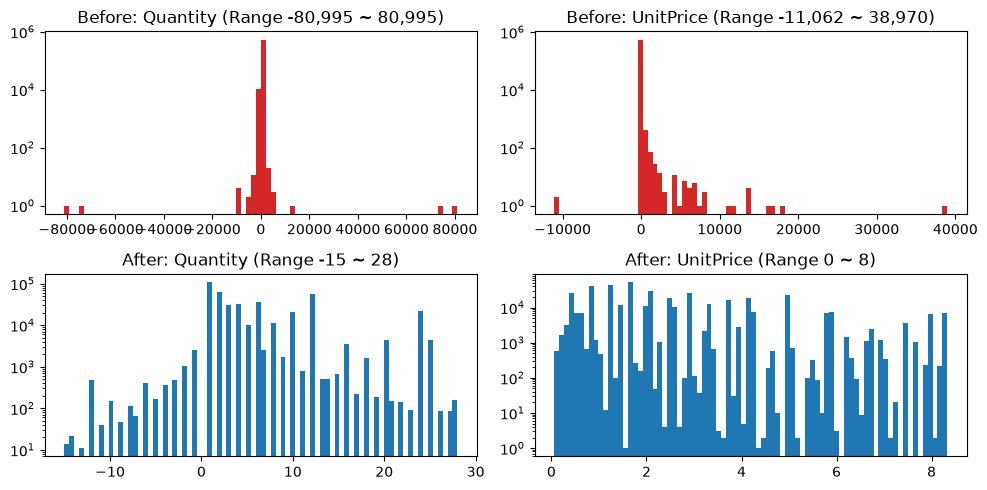

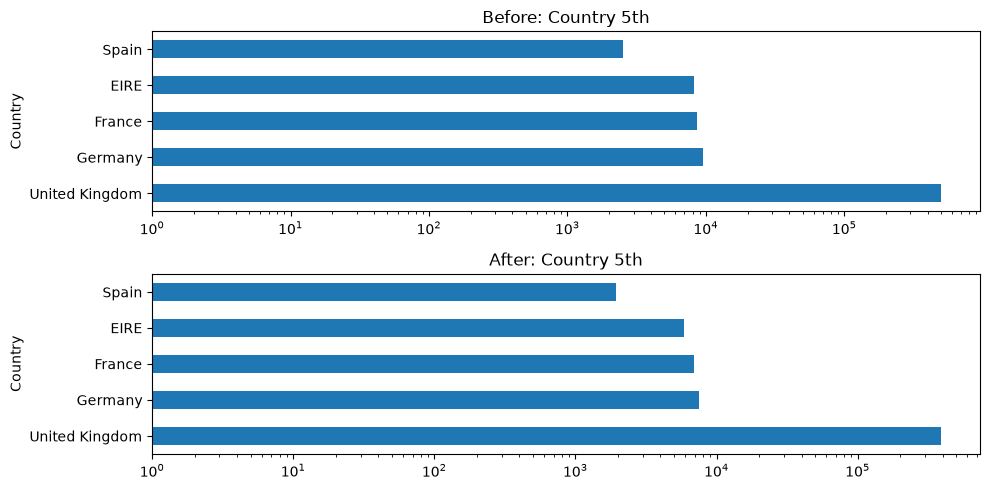

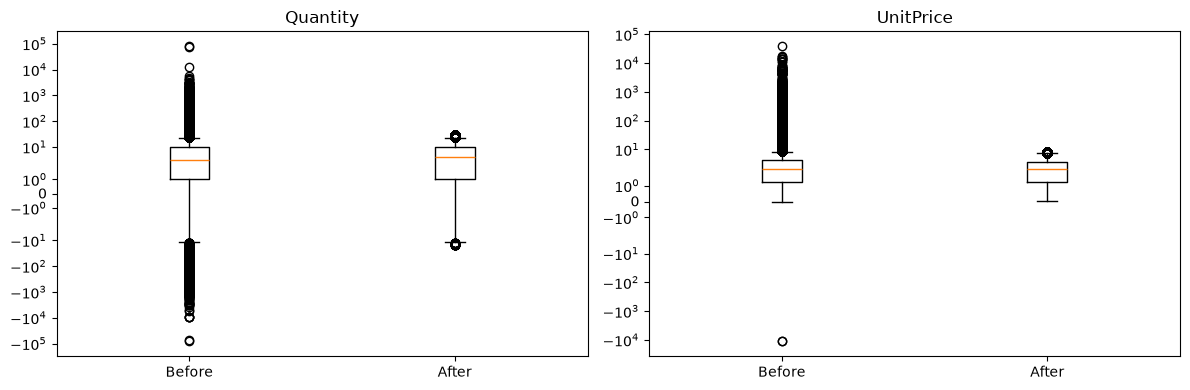

                  전      후        전      후         전         후
                min    min      max    max      mean      mean
Quantity  -80995.00 -15.00  80995.0  28.00  9.552250  6.148133
UnitPrice -11062.06   0.06  38970.0   8.33  4.611114  2.590427


In [55]:
# 전처리 전후 별도 축

fig, axes = plt.subplots(2, 2, figsize=(10, 5))

for j, col in enumerate(["Quantity", "UnitPrice"]):
    axes[0, j].hist(raw[col].dropna(), bins=80, color="tab:red", log=True)
    axes[0, j].set_title(f"Before: {col} (Range {raw[col].min():,.0f} ~ {raw[col].max():,.0f})")

    axes[1, j].hist(clean[col], bins=80, color="tab:blue", log=True)
    axes[1, j].set_title(f"After: {col} (Range {clean[col].min():,.0f} ~ {clean[col].max():,.0f})")

plt.tight_layout()
plt.show()


# 국가별 거래 수 (상위 5개)_로그 스케일

fig, axes = plt.subplots(2, 1, figsize=(10, 5))

raw["Country"].value_counts().head(5).plot.barh(ax=axes[0], title="Before: Country 5th", log=True)
clean["Country"].value_counts().head(5).plot.barh(ax=axes[1], title="After: Country 5th", log=True)

plt.tight_layout()
plt.show()

# 박스플롯 + 로그 축

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["Quantity", "UnitPrice"]):
    ax.boxplot([raw[col].dropna(), clean[col]], tick_labels = ["Before", "After"])
    ax.set_title(col)
    ax.set_yscale("symlog")      # 음수와 0을 포함해도 로그 스케일처럼 표시
plt.tight_layout()
plt.show()

# 수치로 비교 (극단값 차이가 바로 보임)
cols = ["Quantity", "UnitPrice"]
stat = pd.concat({"전": raw[cols].describe(percentiles=[.01, .99]).T,
                  "후": clean[cols].describe(percentiles=[.01, .99]).T}, axis=1)
print(stat[[("전", "min"), ("후", "min"), ("전", "max"), ("후", "max"),
            ("전", "mean"), ("후", "mean")]])
